# Which Spotify tracks travel across playlists?

A curation team wants to know what sets apart the tracks that end up on **several** playlists
("travelling" tracks) from the ones that appear on just one. Do they *sound* different, or are they
simply more popular?

**Data:** 32,833 rows from the public Spotify songs dataset (TidyTuesday, Jan 2020), plus a small
lookup table that groups 24 playlist subgenres into 6 genre families. Both files are read directly
from the AAU course repository.

**Origin:** first group assignment of the MSc in Business Data Science, Aalborg University (2026),
by Group 7: Andrei Busuioc, Brett Taylor Ulsh, Iva Omrcen, Junayed Ahmad Sojib and
Morten Lybye Verwohlt. This version was cleaned up and extended by Andrei Busuioc: a bug in the
original release-year check is fixed, and the genre-family keys are repaired from the data instead
of by guesswork.

**Contents**
1. What is one row?
2. Release dates
3. Repairing the genre-family lookup
4. Travelling vs. non-travelling tracks
5. Is it really popularity, or just age?
6. Inside each genre family
7. Findings, limits and decision log

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

SONGS_URL = "https://raw.githubusercontent.com/aaubs/ds-master/codex/m1-pandas-2026/data/M1_2026/spotify_songs.csv"
FAMILIES_URL = "https://raw.githubusercontent.com/aaubs/ds-master/codex/m1-pandas-2026/data/M1_2026/subgenre_families.csv"

songs_raw = pd.read_csv(SONGS_URL)
families_raw = pd.read_csv(FAMILIES_URL)

print(f"songs_raw:    {songs_raw.shape[0]:,} rows x {songs_raw.shape[1]} columns")
print(f"families_raw: {families_raw.shape[0]:,} rows x {families_raw.shape[1]} columns")

songs_raw:    32,833 rows x 23 columns
families_raw: 24 rows x 2 columns


## 1 · What is one row?

The file looks like a list of songs, but the same `track_id` appears many times. Looking at the
most repeated track shows why.

In [2]:
dup_id = songs_raw["track_id"].value_counts().idxmax()
example = songs_raw[songs_raw["track_id"] == dup_id]
example[["track_name", "track_artist", "playlist_name", "playlist_subgenre"]]

,track_name,track_artist,playlist_name,playlist_subgenre
133,Closer (feat. Halsey),The Chainsmokers,Dance Pop,dance pop
1731,Closer (feat. Halsey),The Chainsmokers,Post pop teen,post-teen pop
2478,Closer (feat. Halsey),The Chainsmokers,Electropop Hits 2017-2020,electropop
4535,Closer (feat. Halsey),The Chainsmokers,A Loose Definition of Indie Poptimism,indie poptimism
7369,Closer (feat. Halsey),The Chainsmokers,◤ Hip Hop Dance Music – Urban – Trap – Breakin...,southern hip hop
17467,Closer (feat. Halsey),The Chainsmokers,Tropical House Run 190 BPM,tropical
18358,Closer (feat. Halsey),The Chainsmokers,2020 Hits & 2019 Hits – Top Global Tracks 🔥🔥🔥,latin pop
19770,Closer (feat. Halsey),The Chainsmokers,2020 Hits & 2019 Hits – Top Global Tracks 🔥🔥🔥,latin hip hop
23784,Closer (feat. Halsey),The Chainsmokers,2020 Hits & 2019 Hits – Top Global Tracks 🔥🔥🔥,hip pop
30629,Closer (feat. Halsey),The Chainsmokers,2015 songs,pop edm


One row is **one appearance of a track on a playlist**. This track has 10 rows but sits on only
8 distinct playlists: one playlist ("2020 Hits & 2019 Hits") lists it three times, each time under a
different subgenre. So counting rows would overstate how far a track travels. We count **distinct playlists** instead.

In [3]:
n_playlists = songs_raw.groupby("track_id")["playlist_id"].nunique().rename("n_playlists")

print(f"Rows for the example track:          {len(example)}")
print(f"Distinct playlists for that track:   {n_playlists[dup_id]}")
print(f"Rows repeating a (track, playlist):  {songs_raw.duplicated(['track_id', 'playlist_id']).sum():,}")
print()
print("Tracks by number of playlists they appear on:")
print(n_playlists.value_counts().sort_index().to_string())

Rows for the example track:          10
Distinct playlists for that track:   8
Rows repeating a (track, playlist):  582

Tracks by number of playlists they appear on:
n_playlists
1    25538
2     2113
3      481
4      130
5       51
6       34
7        7
8        2


About **90 % of tracks appear on a single playlist**. Only 2,818 of 28,356 tracks appear on two
or more, and just 94 on five or more.

Our working table has **one row per track**. Audio features and popularity are the same on every
row of a track, so we can take them from any of its rows.

In [4]:
tracks = (songs_raw.drop_duplicates("track_id")
          .drop(columns=["playlist_name", "playlist_id", "playlist_genre", "playlist_subgenre"])
          .merge(n_playlists, left_on="track_id", right_index=True)
          .reset_index(drop=True))

assert tracks["track_id"].is_unique
print(f"tracks: {len(tracks):,} rows (one per track)")
print("Missing values in the columns we use:",
      tracks[["track_popularity", "danceability", "energy", "valence", "track_album_release_date"]]
      .isna().sum().sum())

tracks: 28,356 rows (one per track)
Missing values in the columns we use: 0


## 2 · Release dates

Release dates are recorded at three different precisions.

In [5]:
date_str = tracks["track_album_release_date"].astype(str)
precision = date_str.str.len().map({10: "day (YYYY-MM-DD)", 7: "month (YYYY-MM)", 4: "year (YYYY)"})
print(precision.value_counts().to_string())

tracks["release_year"] = date_str.str[:4].astype(int)

track_album_release_date
day (YYYY-MM-DD)    26675
year (YYYY)          1656
month (YYYY-MM)        25


Every date has a reliable **year**, but not all have a month or a day. Parsing them all to full
dates would silently turn `2012` into `2012-01-01`, inventing a precise date that the data never
recorded. So we keep the **year only**, which is all the analysis needs.

## 3 · Repairing the genre-family lookup

The lookup table should map each subgenre to exactly one family. It doesn't.

In [6]:
dupes = families_raw[families_raw["subgenre"].duplicated(keep=False)]
print("Subgenres listed twice:")
print(dupes.to_string(index=False))

unmatched = sorted(set(songs_raw["playlist_subgenre"]) - set(families_raw["subgenre"]))
print("\nSubgenres in the songs file with no exact match in the lookup:", unmatched)

Subgenres listed twice:
 subgenre          family
dance pop club_electronic
dance pop       pop_craft

Subgenres in the songs file with no exact match in the lookup: ['neo soul', 'tropical']


Three problems:

| Problem | What is really going on |
|---|---|
| `dance pop` is mapped to both `club_electronic` and `pop_craft` | a genuine conflict in the lookup |
| `neo soul` has no match | the lookup spells it `Neo Soul`: a **capitalisation** mismatch, not a missing entry |
| `tropical` has no match | genuinely missing from the lookup |

Instead of guessing, we let the playlists' own top-level `playlist_genre` settle it.

In [7]:
check = ["dance pop", "neo soul", "tropical"]
pd.crosstab(songs_raw["playlist_subgenre"], songs_raw["playlist_genre"]).loc[check]

playlist_genre,edm,latin,pop,r&b,rap,rock
playlist_subgenre,,,,,,
dance pop,0,0,1298,0,0,0
neo soul,0,0,0,1637,0,0
tropical,0,1288,0,0,0,0


The evidence is unambiguous:

* every `dance pop` playlist is a **pop** playlist, so it belongs in `pop_craft` (the other pop
  subgenres' family), not `club_electronic`;
* `neo soul` only appears in **r&b** playlists, matching `soul_rnb` once the spelling is fixed;
* `tropical` only appears in **latin** playlists, alongside `latin pop` and `reggaeton`
  (`latin_rhythm`).

With these three fixes **every track gets a family**. A naive merge would have left 2,636 tracks
unlabelled.

In [8]:
families = families_raw.assign(subgenre=families_raw["subgenre"].str.strip().str.lower())
families = families[~((families["subgenre"] == "dance pop") & (families["family"] == "club_electronic"))]
families = pd.concat([families, pd.DataFrame({"subgenre": ["tropical"], "family": ["latin_rhythm"]})],
                     ignore_index=True)
assert families["subgenre"].is_unique

rows = songs_raw[["track_id", "playlist_subgenre"]].merge(
    families, left_on="playlist_subgenre", right_on="subgenre",
    how="left", validate="many_to_one")
assert len(rows) == len(songs_raw) and rows["family"].notna().all()
print(f"Rows after the merge: {len(rows):,} (expected {len(songs_raw):,}); unlabelled: {rows['family'].isna().sum()}")

Rows after the merge: 32,833 (expected 32,833); unlabelled: 0


One more subtlety: a family belongs to a **playlist**, not to a track. A track that travels can
sit on playlists from different families, so taking the family from its first row (as a plain
`drop_duplicates` would) picks one arbitrarily. We give each track its **most common** family
across its playlists and count how many tracks this affects.

In [9]:
family_counts = rows.groupby(["track_id", "family"]).size().reset_index(name="n")
track_family = (family_counts.sort_values(["track_id", "n"], ascending=[True, False])
                .drop_duplicates("track_id")
                .set_index("track_id")["family"])
n_families = family_counts.groupby("track_id")["family"].nunique()

tracks["family"] = tracks["track_id"].map(track_family)
tracks["mixed_family"] = tracks["track_id"].map(n_families) > 1

print(f"Tracks whose playlists span more than one family: {tracks['mixed_family'].sum():,} "
      f"({tracks['mixed_family'].mean():.1%} of all tracks)")

Tracks whose playlists span more than one family: 1,797 (6.3% of all tracks)


## 4 · Travelling vs. non-travelling tracks

We call a track **travelling** if it appears on **2 or more** playlists. Since 90 % of tracks sit
on one playlist, this already marks the top ~10 %. Because any cut-off is a choice, we also check
3+ and 5+. Every mean is shown next to the number of tracks behind it.

In [10]:
FEATURES = ["danceability", "energy", "valence", "track_popularity"]

def compare(df, cutoff):
    """Mean features for tracks on >= cutoff playlists vs. the rest, with counts."""
    group = np.where(df["n_playlists"] >= cutoff, "travelling", "single / few")
    out = df.groupby(group)[FEATURES].mean().round(3)
    out.insert(0, "n_tracks", df.groupby(group).size())
    out.insert(0, "cutoff", f"{cutoff}+")
    return out

robustness = pd.concat([compare(tracks, c) for c in (2, 3, 5)])
robustness

,cutoff,n_tracks,danceability,energy,valence,track_popularity
single / few,2+,25538,0.652,0.698,0.509,37.099
travelling,2+,2818,0.666,0.705,0.522,59.544
single / few,3+,27651,0.653,0.698,0.510,38.513
travelling,3+,705,0.669,0.708,0.532,71.376
single / few,5+,28262,0.653,0.699,0.510,39.180
travelling,5+,94,0.700,0.641,0.496,84.479


* **The audio features barely move.** At 2+ and 3+, danceability, energy and valence differ by
  about 0.01–0.02 on a 0–1 scale. At 5+ the differences reach ~0.05, but on only 94 tracks.
  Travelling tracks do not *sound* noticeably different.
* **Popularity does.** Travelling tracks average about 60 vs. 37, and the gap widens as the
  definition gets stricter (≈ 71 at 3+, ≈ 84 at 5+).
* The 5+ group has only 94 tracks, so its numbers are the least stable.

From here on, *travelling* means **2+ playlists**. The flag is stored once, in its own column, so
later cells can't accidentally pick up a different cut-off.

In [11]:
tracks["travelling"] = tracks["n_playlists"] >= 2
tracks["travelling"].value_counts()

travelling
False    25538
True      2818
Name: count, dtype: int64

## 5 · Is it really popularity, or just age?

Newer songs tend to be more popular on Spotify, and playlists favour recent hits. If travelling
tracks were simply newer, the popularity gap could be a release-year effect.

*(The original assignment answered this with the flag still set to the 5+ cut-off from the loop
above, so it compared 94 tracks against everything else. Here it uses the 2+ definition.)*

In [12]:
print(tracks.groupby("travelling")["release_year"].agg(["mean", "median", "size"]).round(1).to_string())

              mean  median   size
travelling                       
False       2011.2  2016.0  25538
True        2010.0  2016.0   2818


Both groups have the same **median release year (2016)**, so travelling tracks are not
systematically newer. The fairer test is to compare popularity **within the same era**, so
like is compared with like.

In [13]:
eras = pd.cut(tracks["release_year"], bins=[0, 1999, 2009, 2014, 2017, 2018, 2019, 2020],
              labels=["before 2000", "2000–09", "2010–14", "2015–17", "2018", "2019", "2020"])

by_era = (tracks.groupby([eras, "travelling"], observed=True)["track_popularity"]
          .agg(["mean", "size"]).unstack("travelling"))
by_era.columns = ["pop_single", "pop_travelling", "n_single", "n_travelling"]
by_era["gap"] = by_era["pop_travelling"] - by_era["pop_single"]
by_era.round(1)

,pop_single,pop_travelling,n_single,n_travelling,gap
release_year,,,,,
before 2000,38.3,56.0,3558,531,17.8
2000–09,30.2,57.5,3562,245,27.4
2010–14,29.5,55.7,3666,293,26.2
2015–17,34.2,55.2,5009,543,21.1
2018,40.4,66.0,2669,248,25.6
2019,45.1,65.0,6535,871,19.9
2020,41.0,53.7,539,87,12.7


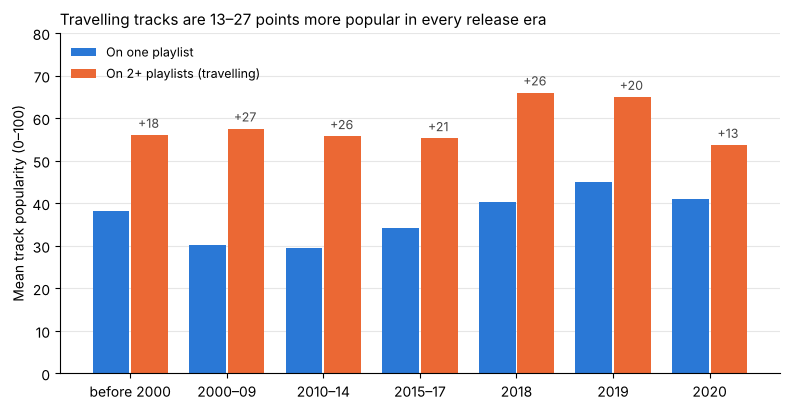

In [14]:
BLUE, ORANGE = "#2a78d6", "#eb6834"   # colour-blind-safe pair

fig, ax = plt.subplots(figsize=(8, 4.2))
x = np.arange(len(by_era))
w = 0.38
ax.bar(x - w/2 - 0.01, by_era["pop_single"], w, color=BLUE, label="On one playlist")
ax.bar(x + w/2 + 0.01, by_era["pop_travelling"], w, color=ORANGE, label="On 2+ playlists (travelling)")

for i, (a, b) in enumerate(zip(by_era["pop_single"], by_era["pop_travelling"])):
    ax.text(i + w/2, b + 1, f"+{b - a:.0f}", ha="center", va="bottom", fontsize=9, color="#444")

ax.set_xticks(x, by_era.index)
ax.set_ylabel("Mean track popularity (0–100)")
ax.set_ylim(0, 80)
ax.set_title("Travelling tracks are 13–27 points more popular in every release era",
             loc="left", fontsize=11)
ax.spines[["top", "right"]].set_visible(False)
ax.yaxis.grid(True, color="#e6e6e6"); ax.set_axisbelow(True)
ax.legend(frameon=False, loc="upper left", fontsize=9)
plt.tight_layout()
plt.show()

The gap holds **in every era**, from older catalogue tracks to 2020 releases, so it is not
explained by travelling tracks being newer.

One more check: about 10 % of single-playlist tracks have a popularity of exactly **0** (often
re-uploads or duplicate album versions), against 1 % of travelling tracks. Do those zeros create
the gap?

In [15]:
nonzero = tracks[tracks["track_popularity"] > 0]
print("Share with popularity 0:")
print(tracks.groupby("travelling")["track_popularity"].apply(lambda s: (s == 0).mean()).round(3).to_string())
print("\nMean popularity, excluding zeros:")
print(nonzero.groupby("travelling")["track_popularity"].agg(["mean", "size"]).round(1).to_string())

Share with popularity 0:
travelling
False    0.101
True     0.011

Mean popularity, excluding zeros:
            mean   size
travelling             
False       41.3  22948
True        60.2   2788


Excluding the zeros narrows the gap (≈ 41 vs. 60) but it remains large.

## 6 · Inside each genre family

Is the pattern the same across genres, and are any families too small to say?

In [16]:
by_family = tracks.groupby("family").agg(
    n_tracks=("track_id", "size"),
    n_travelling=("travelling", "sum"),
    share_travelling=("travelling", "mean"),
)
pop = tracks.groupby(["family", "travelling"])["track_popularity"].mean().unstack()
by_family["pop_single"] = pop[False]
by_family["pop_travelling"] = pop[True]
by_family["gap"] = by_family["pop_travelling"] - by_family["pop_single"]
by_family.sort_values("share_travelling").round(3)

,n_tracks,n_travelling,share_travelling,pop_single,pop_travelling,gap
family,,,,,,
soul_rnb,4504,234,0.052,34.961,61.004,26.043
pop_craft,4452,383,0.086,40.992,68.935,27.943
latin_rhythm,2855,284,0.099,42.535,64.493,21.958
hiphop_lineage,6727,714,0.106,38.299,63.245,24.946
guitar_rock,4435,492,0.111,38.331,56.140,17.810
club_electronic,5383,711,0.132,30.088,50.665,20.577


* Every family has at least ~200 travelling tracks, so **none is too thin** to compare.
* The **share** of tracks that travel varies a lot by family: from about 5 % of soul/R&B tracks
  to 13 % of club/electronic tracks.
* This ranking depends on how a family is assigned. Taking each track's family from its first row
  (as the original assignment did) put pop and latin on top instead, a reminder that the
  family step is a real decision, not a formality.
* The popularity gap appears in **every** family.

**A better grouping?** The supplied families mix very different subgenres (e.g. `hip pop` sits in
`soul_rnb`). The playlists' own `playlist_genre` (6 values: pop, rap, rock, latin, r&b, edm) is
an alternative that needs no external lookup and no manual fixes.

## 7 · Findings, limits and decision log

### What we found

Only about 1 in 10 tracks appears on more than one playlist. Those travelling tracks **sound almost
the same** as everything else: their danceability, energy and valence are within about 0.02 of
the other tracks. What sets them apart is **popularity**: about 60 vs. 37 on average, a gap that grows
with a stricter definition of "travelling", holds in every release era and in every genre family,
and survives removing zero-popularity tracks.

For a curation team, this suggests that cross-playlist placement tracks **reach** rather than
**sound**: audio features alone would not help predict which tracks spread.

### What this data can't tell us

1. **Direction of cause.** A track may be popular *because* it is on many playlists, or put on
   many playlists *because* it is already popular. A single snapshot can't separate the two.
2. **What actually drives selection.** Three audio features are a thin description of a song.
   Artist fame, label promotion, release timing and editorial relationships are not in the data.
3. **Representativeness.** The playlists are a sample collected for this dataset, not all of
   Spotify, and `track_popularity` is one snapshot from early 2020.

### Decision log

| Step | Decision | What it costs |
|---|---|---|
| Unit | One row per `track_id`; playlists counted with `nunique` | the same song released as a remix or on another album counts as a separate track |
| Dates | Keep the release **year** only | month and day are discarded where they exist |
| `dance pop` | Map to `pop_craft`, because all its playlists are pop playlists | relies on `playlist_genre` being labelled consistently |
| `Neo Soul` | Normalise case and spaces before merging | none: it's a spelling fix |
| `tropical` | Add to `latin_rhythm`, because all its playlists are latin | an assumption the lookup's authors may not share |
| Family per track | Most common family across the track's playlists | the 'mixed family' tracks counted above are simplified to one family |
| Travelling | 2+ distinct playlists; 3+ and 5+ checked | any threshold is arbitrary; results are shown for all three |

### Tools

pandas and matplotlib. Claude (Anthropic) was used for help with syntax and for reviewing this
cleaned-up version.